# 01 — Load, Merge & Preprocess Real UNHCR Data

**Goal:** Load the 3 most useful Kaggle files, clean them, merge on year + country,
engineer demographic ratio features, derive UNHCR-standard resource targets,
and save a single `camp_features.csv` ready for model training.

**Files used from `data/raw/`:**
- `population.csv` — primary refugee/IDP counts per country pair (2010–2022)
- `demographics.csv` — age/gender breakdown by location (2001–2016)
- `asylum_seekers_monthly.csv` — monthly arrivals, used to compute arrival-rate feature

Run cells top-to-bottom.

## 1. Imports & Paths

In [1]:
import sys
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from pathlib import Path

In [2]:
import sys
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from pathlib import Path

print(f'Python : {sys.version}')
print(f'NumPy  : {np.__version__}')
print(f'Pandas : {pd.__version__}')

RAW       = Path('../data/raw')
PROCESSED = Path('../data/processed')
PROCESSED.mkdir(parents=True, exist_ok=True)

pd.set_option('display.max_columns', 30)
pd.set_option('display.float_format', '{:,.1f}'.format)

print('\nCSV files in data/raw:')
for f in sorted(RAW.glob('*.csv')):
    print(f'  {f.name}  ({f.stat().st_size / 1e6:.1f} MB)')

Python : 3.12.3 (main, Mar 23 2026, 19:04:32) [GCC 13.3.0]
NumPy  : 2.4.4
Pandas : 3.0.2

CSV files in data/raw:
  asylum_seekers.csv  (7.1 MB)
  asylum_seekers_monthly.csv  (12.2 MB)
  demographics.csv  (1.4 MB)
  persons_of_concern.csv  (4.7 MB)
  population.csv  (4.2 MB)
  resettlement.csv  (0.3 MB)
  time_series.csv  (15.7 MB)


## 2. Load `population.csv` — Primary Dataset

Cleanest file: all numeric columns, covers 2010–2022.  
Each row = one (origin country, asylum country, year) combination.

In [3]:
pop_raw = pd.read_csv(RAW / 'population.csv', low_memory=False)
print(f'Shape  : {pop_raw.shape[0]:,} rows x {pop_raw.shape[1]} cols')
print(f'Years  : {pop_raw.year.min()} - {pop_raw.year.max()}')
print(f'Host countries  : {pop_raw.coa_name.nunique()}')
print(f'Origin countries: {pop_raw.coo_name.nunique()}')
print()
pop_raw.head()

Shape  : 64,809 rows x 16 cols
Years  : 2010 - 2022
Host countries  : 189
Origin countries: 210



,year,coo_name,coo,coo_iso,coa_name,coa,coa_iso,refugees,asylum_seekers,returned_refugees,idps,returned_idps,stateless,ooc,oip,hst
0,2010,Afghanistan,AFG,AFG,Afghanistan,AFG,AFG,0,0,0,351907,3366,0,838250,NaN,NaN
1,2010,Iran (Islamic Rep. of),IRN,IRN,Afghanistan,AFG,AFG,30,21,0,0,0,0,0,NaN,NaN
2,2010,Iraq,IRQ,IRQ,Afghanistan,AFG,AFG,6,0,0,0,0,0,0,NaN,NaN
3,2010,Pakistan,PAK,PAK,Afghanistan,AFG,AFG,6398,9,0,0,0,0,0,NaN,NaN
4,2010,Egypt,ARE,EGY,Albania,ALB,ALB,5,0,0,0,0,0,0,NaN,NaN


## 3. Clean & Aggregate Population Data

Group by **(year, country of asylum)** — one row per host country per year,
which represents the total displaced population a camp system must support.

In [4]:
POP_COLS = ['refugees', 'asylum_seekers', 'returned_refugees',
            'idps', 'returned_idps', 'stateless', 'ooc']

# UNHCR uses '*' to suppress small numbers — replace with 0
for col in POP_COLS:
    pop_raw[col] = pd.to_numeric(
        pop_raw[col].astype(str).str.replace('*', '', regex=False),
        errors='coerce'
    ).fillna(0)

# Aggregate to host-country level per year
pop = (
    pop_raw
    .groupby(['year', 'coa_name', 'coa_iso'], as_index=False)[POP_COLS]
    .sum()
    .rename(columns={'coa_name': 'country', 'coa_iso': 'country_iso'})
)

pop['total_population'] = pop[POP_COLS].sum(axis=1)
pop = pop[pop['total_population'] > 0].copy()

print(f'After aggregation: {pop.shape[0]:,} rows')
print(f'Year range: {pop.year.min()} - {pop.year.max()}')
print()
pop[['refugees', 'idps', 'asylum_seekers', 'stateless', 'total_population']].describe()

After aggregation: 2,251 rows
Year range: 2010 - 2022



,refugees,idps,asylum_seekers,stateless,total_population
count,"2,251.0","2,251.0","2,251.0","2,251.0","2,251.0"
mean,"99,042.1","204,092.1","16,243.0","21,784.2","376,204.1"
std,"307,475.7","852,465.6","76,747.2","105,073.2","1,022,216.2"
min,0.0,0.0,0.0,0.0,5.0
25%,310.5,0.0,56.0,0.0,"2,099.0"
50%,"4,050.0",0.0,654.0,0.0,"21,797.0"
75%,"56,502.5",0.0,"6,518.0","1,200.0","226,548.5"
max,"3,759,817.0","8,252,788.0","1,798,792.0","955,399.0","8,773,689.0"


## 4. Load `demographics.csv` — Age & Gender Ratios

Covers 2001-2016 with age/gender breakdown per location.  
We derive three ratios that directly affect resource planning:

| Ratio | Why it matters |
|---|---|
| `children_ratio` (under 18) | Higher food calories, vaccines, education space |
| `elderly_ratio` (60+) | Higher chronic disease care, mobility-friendly shelter |
| `female_ratio` | Maternal health, gender-specific sanitation, protection needs |

In [5]:
demo_raw = pd.read_csv(RAW / 'demographics.csv', low_memory=False)
demo_raw = demo_raw.rename(columns={
    'Country / territory of asylum/residence': 'country',
    'Year': 'year'
})
print(f'Shape: {demo_raw.shape[0]:,} rows x {demo_raw.shape[1]} cols')
demo_raw.head(3)

Shape: 18,356 rows x 19 cols


,year,country,Location Name,Female 0-4,Female 5-11,Female 5-17,Female 12-17,Female 18-59,Female 60+,F: Unknown,F: Total,Male 0-4,Male 5-11,Male 5-17,Male 12-17,Male 18-59,Male 60+,M: Unknown,M: Total
0,2001,Afghanistan,Kabul,0,NaN,1.0,NaN,1,0,0.0,2,0,NaN,0.0,NaN,2,0,0.0,2
1,2001,Afghanistan,Various,14335,NaN,"45,451.0",NaN,99880,19234,"412,004.0",590904,14716,NaN,"47,522.0",NaN,114965,13025,"435,492.0",625720
2,2001,Afghanistan,Herat,0,NaN,0.0,NaN,1,0,0.0,1,0,NaN,0.0,NaN,1,0,0.0,1


In [6]:
# 'Female 5-17' and 'Male 5-17' are aggregates of 5-11 + 12-17 (83% null).
# Use the sub-bands instead to avoid double-counting.
CHILD_COLS   = ['Female 0-4', 'Female 5-11', 'Female 12-17',
                'Male 0-4',   'Male 5-11',   'Male 12-17']
ELDERLY_COLS = ['Female 60+', 'Male 60+']
FEMALE_COLS  = ['Female 0-4', 'Female 5-11', 'Female 12-17', 'Female 18-59', 'Female 60+']
MALE_COLS    = ['Male 0-4',   'Male 5-11',   'Male 12-17',   'Male 18-59',   'Male 60+']
ALL_DEMO_COLS = list(set(CHILD_COLS + ELDERLY_COLS + FEMALE_COLS + MALE_COLS))

for col in ALL_DEMO_COLS:
    demo_raw[col] = pd.to_numeric(demo_raw[col], errors='coerce').fillna(0)

# Aggregate to (year, country) — sum across all camp locations within a country
demo = demo_raw.groupby(['year', 'country'], as_index=False)[ALL_DEMO_COLS].sum()

demo['n_children'] = demo[CHILD_COLS].sum(axis=1)
demo['n_elderly']  = demo[ELDERLY_COLS].sum(axis=1)
demo['n_female']   = demo[FEMALE_COLS].sum(axis=1)
demo['n_male']     = demo[MALE_COLS].sum(axis=1)
demo['demo_total'] = demo['n_female'] + demo['n_male']

safe = demo['demo_total'].replace(0, np.nan)
demo['children_ratio'] = (demo['n_children'] / safe).clip(0, 1)
demo['elderly_ratio']  = (demo['n_elderly']  / safe).clip(0, 1)
demo['female_ratio']   = (demo['n_female']   / safe).clip(0, 1)

demo = demo[['year', 'country', 'children_ratio', 'elderly_ratio', 'female_ratio']].dropna()
print(f'Demographics processed: {demo.shape[0]:,} rows')
print(f'Year range: {demo.year.min()} - {demo.year.max()}')
demo[['children_ratio', 'elderly_ratio', 'female_ratio']].describe()

Demographics processed: 1,950 rows
Year range: 2001 - 2016


,children_ratio,elderly_ratio,female_ratio
count,"1,950.0","1,950.0","1,950.0"
mean,0.3,0.0,0.4
std,0.2,0.1,0.1
min,0.0,0.0,0.0
25%,0.1,0.0,0.3
50%,0.3,0.0,0.4
75%,0.4,0.1,0.5
max,1.0,1.0,1.0


## 5. Load `asylum_seekers_monthly.csv` — Arrival Rate Feature

Monthly granularity lets us compute **year-over-year arrival growth** per host country.
A camp with a rapidly growing population needs surge resources — the growth rate captures this urgency.

In [7]:
monthly_raw = pd.read_csv(RAW / 'asylum_seekers_monthly.csv', low_memory=False)
monthly_raw = monthly_raw.rename(columns={
    'Country / territory of asylum/residence': 'country',
    'Year': 'year',
    'Month': 'month',
    'Value': 'monthly_arrivals'
})
monthly_raw['monthly_arrivals'] = pd.to_numeric(monthly_raw['monthly_arrivals'], errors='coerce').fillna(0)

# Sum to yearly totals per country
yearly_arrivals = (
    monthly_raw
    .groupby(['year', 'country'], as_index=False)['monthly_arrivals']
    .sum()
    .rename(columns={'monthly_arrivals': 'yearly_arrivals'})
    .sort_values(['country', 'year'])
)

# Year-over-year growth rate
yearly_arrivals['prev_year_arrivals'] = (
    yearly_arrivals.groupby('country')['yearly_arrivals'].shift(1)
)
yearly_arrivals['arrival_growth_rate'] = (
    (yearly_arrivals['yearly_arrivals'] - yearly_arrivals['prev_year_arrivals'])
    / yearly_arrivals['prev_year_arrivals'].replace(0, np.nan)
).clip(-5, 5).fillna(0)  # cap at +/-500% to avoid extreme outlier distortion

monthly_feat = yearly_arrivals[['year', 'country', 'yearly_arrivals', 'arrival_growth_rate']].copy()
print(f'Arrival features: {monthly_feat.shape[0]:,} rows')
print(f'Year range: {monthly_feat.year.min()} - {monthly_feat.year.max()}')
monthly_feat[['yearly_arrivals', 'arrival_growth_rate']].describe()

Arrival features: 785 rows
Year range: 1999 - 2017


,yearly_arrivals,arrival_growth_rate
count,785.0,785.0
mean,"13,837.3",0.2
std,"36,339.4",0.9
min,2.0,-1.0
25%,442.0,-0.3
50%,"3,414.0",0.0
75%,"15,563.0",0.4
max,"721,778.0",5.0


## 6. Merge All Datasets

`population.csv` is the base (left side). Demographics and arrival-rate features
join where year + country match. Missing demographic ratios (rows outside 2010-2016
overlap) are filled with the global median — a sensible humanitarian fallback.

In [8]:
df = pop.merge(demo,         on=['year', 'country'], how='left')
df = df.merge(monthly_feat,  on=['year', 'country'], how='left')

# Fill missing ratios with global medians from the demographics dataset
for col in ['children_ratio', 'elderly_ratio', 'female_ratio']:
    median_val = demo[col].median()
    missing_n  = df[col].isna().sum()
    df[col]    = df[col].fillna(median_val)
    print(f'  {col}: filled {missing_n} nulls with median={median_val:.3f}')

df['yearly_arrivals']    = df['yearly_arrivals'].fillna(0)
df['arrival_growth_rate'] = df['arrival_growth_rate'].fillna(0)

print(f'\nMerged dataset : {df.shape[0]:,} rows x {df.shape[1]} cols')
print(f'Year range     : {df.year.min()} - {df.year.max()}')
print(f'Host countries : {df.country.nunique()}')
print(f'Remaining nulls: {df.isnull().sum().sum()}')
df.head()

  children_ratio: filled 1365 nulls with median=0.263
  elderly_ratio: filled 1365 nulls with median=0.030
  female_ratio: filled 1365 nulls with median=0.447

Merged dataset : 2,251 rows x 16 cols
Year range     : 2010 - 2022
Host countries : 189
Remaining nulls: 0


,year,country,country_iso,refugees,asylum_seekers,returned_refugees,idps,returned_idps,stateless,ooc,total_population,children_ratio,elderly_ratio,female_ratio,yearly_arrivals,arrival_growth_rate
0,2010,Afghanistan,AFG,6434,30,0,351907,3366,0,838250,1199987,0.5,0.1,0.5,0.0,0.0
1,2010,Albania,ALB,75,20,0,0,0,0,0,95,0.3,0.1,0.3,12.0,3.0
2,2010,Algeria,DZA,94141,300,0,0,0,0,0,94441,0.2,0.0,0.3,0.0,0.0
3,2010,Angola,AGO,15142,4228,0,0,0,0,0,19370,0.3,0.0,0.4,0.0,0.0
4,2010,Argentina,ARG,3257,916,0,0,0,0,0,4173,0.3,0.0,0.4,0.0,0.0


## 7. Derive Resource Target Columns

Using **UNHCR / Sphere Project Humanitarian Standards** to convert population counts
into concrete daily resource needs. These are the **target (y) variables** the model will predict.

| Resource | Standard | Formula |
|---|---|---|
| Food | 2,100 kcal/person/day ≈ 0.6 kg dry rations | `total_pop × 0.6` |
| Water | 20 litres/person/day minimum | `total_pop × 20` |
| Shelter | 1 unit per 4.5 persons (Sphere standard) | `total_pop / 4.5` |
| Medical staff | Base 1 per 500, +extra for children and elderly | adjusted formula |

The medical target applies demographic weights: children need 2× attention,
elderly need 3× attention compared to working-age adults.

In [9]:
n = df['total_population']

df['food_kg_day']      = (n * 0.6).round(1)
df['water_liters_day'] = (n * 20).round(1)
df['shelter_units']    = (n / 4.5).round().astype(int)
df['medical_staff_needed'] = (
    n / 500
    + df['children_ratio'] * n * 0.002
    + df['elderly_ratio']  * n * 0.003
).round(1)

TARGET_COLS = ['food_kg_day', 'water_liters_day', 'shelter_units', 'medical_staff_needed']

print('Resource target summary:')
df[TARGET_COLS].describe()

Resource target summary:


,food_kg_day,water_liters_day,shelter_units,medical_staff_needed
count,"2,251.0","2,251.0","2,251.0","2,251.0"
mean,"225,722.5","7,524,083.0","83,600.9","1,036.3"
std,"613,329.7","20,444,323.7","227,159.1","2,805.2"
min,3.0,100.0,1.0,0.0
25%,"1,259.4","41,980.0",466.0,5.3
50%,"13,078.2","435,940.0","4,844.0",60.0
75%,"135,929.1","4,530,970.0","50,344.0",624.0
max,"5,264,213.4","175,473,780.0","1,949,709.0","28,752.2"


## 8. Feature Set Summary

In [10]:
FEATURE_COLS = [
    'year',
    'refugees', 'asylum_seekers', 'returned_refugees',
    'idps', 'returned_idps', 'stateless', 'ooc',
    'total_population',
    'children_ratio', 'elderly_ratio', 'female_ratio',
    'yearly_arrivals', 'arrival_growth_rate',
]

print(f'Features : {len(FEATURE_COLS)}')
print(f'Targets  : {len(TARGET_COLS)}')
print(f'ID cols  : country, country_iso')
print()
print(f'{"Column":<28} {"Role":<10} {"Non-null":<10} {"Mean":>12}')
print('-' * 65)
for col in FEATURE_COLS + TARGET_COLS:
    role = 'TARGET' if col in TARGET_COLS else 'FEATURE'
    non_null = df[col].notna().sum()
    mean_val = df[col].mean() if pd.api.types.is_numeric_dtype(df[col]) else '-'
    mean_str = f'{mean_val:>12,.1f}' if isinstance(mean_val, float) else f'{mean_val:>12}'
    print(f'{col:<28} {role:<10} {non_null:<10} {mean_str}')

Features : 14
Targets  : 4
ID cols  : country, country_iso

Column                       Role       Non-null           Mean
-----------------------------------------------------------------
year                         FEATURE    2251            2,016.0
refugees                     FEATURE    2251           99,042.1
asylum_seekers               FEATURE    2251           16,243.0
returned_refugees            FEATURE    2251            2,115.6
idps                         FEATURE    2251          204,092.1
returned_idps                FEATURE    2251           20,331.1
stateless                    FEATURE    2251           21,784.2
ooc                          FEATURE    2251           12,596.0
total_population             FEATURE    2251          376,204.1
children_ratio               FEATURE    2251                0.3
elderly_ratio                FEATURE    2251                0.0
female_ratio                 FEATURE    2251                0.4
yearly_arrivals              FEATURE    22

## 9. Visualisations

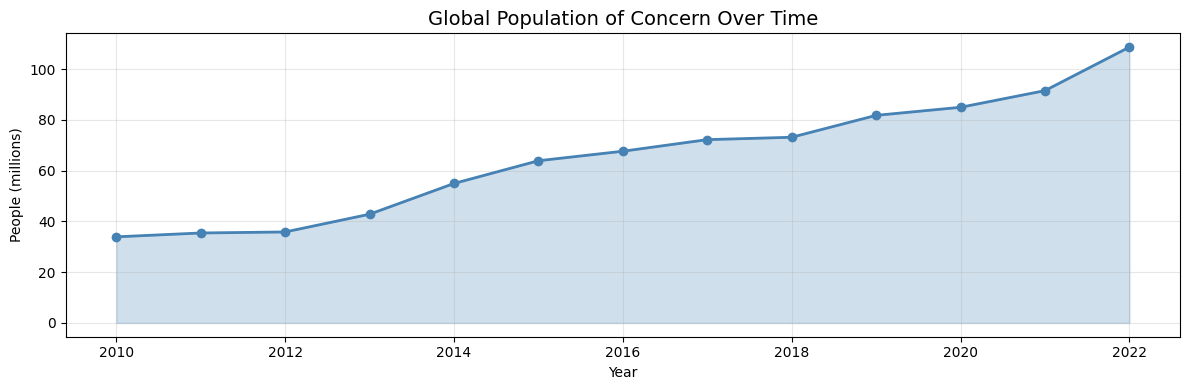

In [11]:
# 9a — Total population of concern over time
yearly = df.groupby('year')['total_population'].sum().reset_index()

fig, ax = plt.subplots(figsize=(12, 4))
ax.fill_between(yearly['year'], yearly['total_population'] / 1e6, alpha=0.25, color='steelblue')
ax.plot(yearly['year'], yearly['total_population'] / 1e6, marker='o', color='steelblue', linewidth=2)
ax.set_title('Global Population of Concern Over Time', fontsize=14)
ax.set_xlabel('Year')
ax.set_ylabel('People (millions)')
ax.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

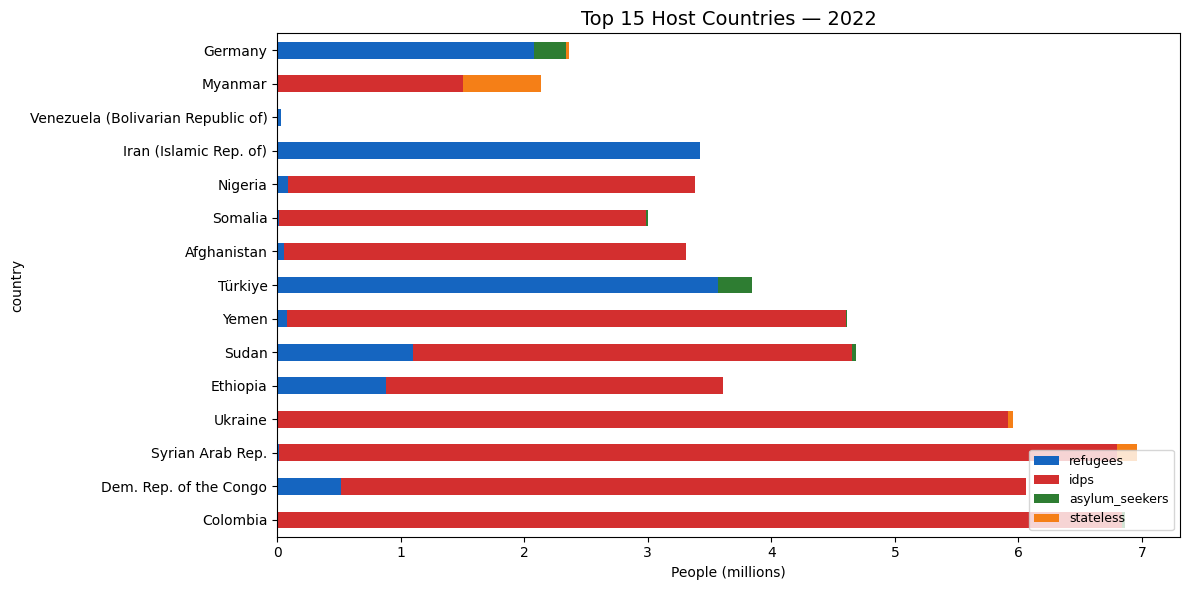

In [12]:
# 9b — Top 15 host countries stacked by population type (most recent year)
latest_year = df['year'].max()
top15 = (
    df[df['year'] == latest_year]
    .nlargest(15, 'total_population')
    .set_index('country')[['refugees', 'idps', 'asylum_seekers', 'stateless']]
)

fig, ax = plt.subplots(figsize=(12, 6))
top15.div(1e6).plot(kind='barh', stacked=True, ax=ax,
                    color=['#1565C0', '#D32F2F', '#2E7D32', '#F57F17'])
ax.set_title(f'Top 15 Host Countries — {latest_year}', fontsize=14)
ax.set_xlabel('People (millions)')
ax.legend(loc='lower right', fontsize=9)
plt.tight_layout()
plt.show()

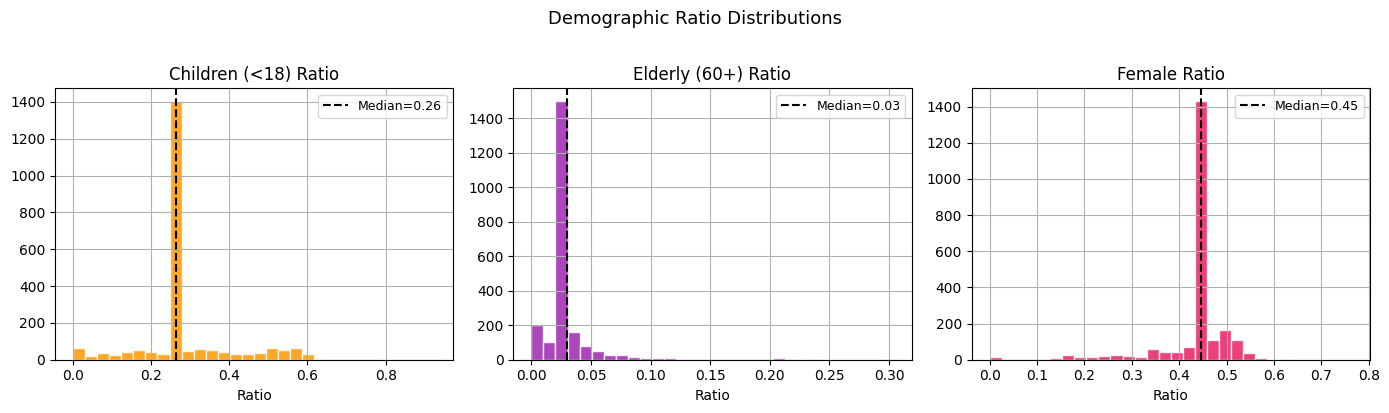

In [13]:
# 9c — Demographic ratio distributions
fig, axes = plt.subplots(1, 3, figsize=(14, 4))
ratio_info = [
    ('children_ratio', 'Children (<18) Ratio', '#FF9800'),
    ('elderly_ratio',  'Elderly (60+) Ratio',  '#9C27B0'),
    ('female_ratio',   'Female Ratio',          '#E91E63'),
]
for ax, (col, title, color) in zip(axes, ratio_info):
    df[col].dropna().hist(bins=30, ax=ax, color=color, edgecolor='white', alpha=0.85)
    med = df[col].median()
    ax.axvline(med, color='black', linestyle='--', linewidth=1.5, label=f'Median={med:.2f}')
    ax.set_title(title, fontsize=12)
    ax.set_xlabel('Ratio')
    ax.legend(fontsize=9)

plt.suptitle('Demographic Ratio Distributions', fontsize=13, y=1.02)
plt.tight_layout()
plt.show()

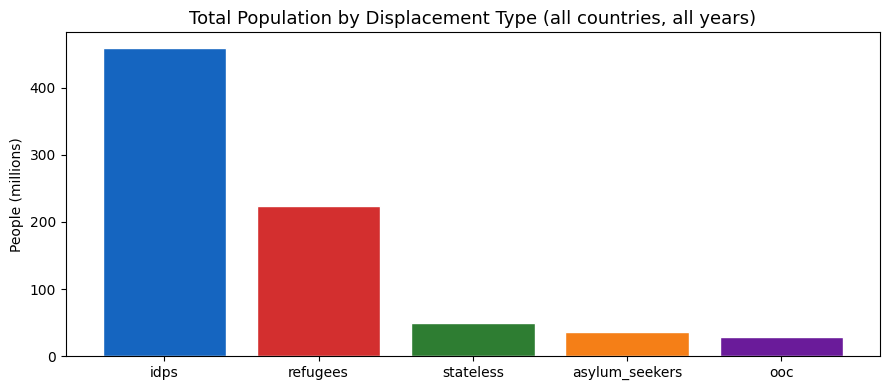

In [14]:
# 9d — Population type breakdown (totals across all years)
type_totals = df[['refugees', 'idps', 'asylum_seekers', 'stateless', 'ooc']].sum().sort_values(ascending=False)

fig, ax = plt.subplots(figsize=(9, 4))
colors = ['#1565C0', '#D32F2F', '#2E7D32', '#F57F17', '#6A1B9A']
ax.bar(type_totals.index, type_totals.values / 1e6, color=colors, edgecolor='white')
ax.set_title('Total Population by Displacement Type (all countries, all years)', fontsize=13)
ax.set_ylabel('People (millions)')
plt.tight_layout()
plt.show()

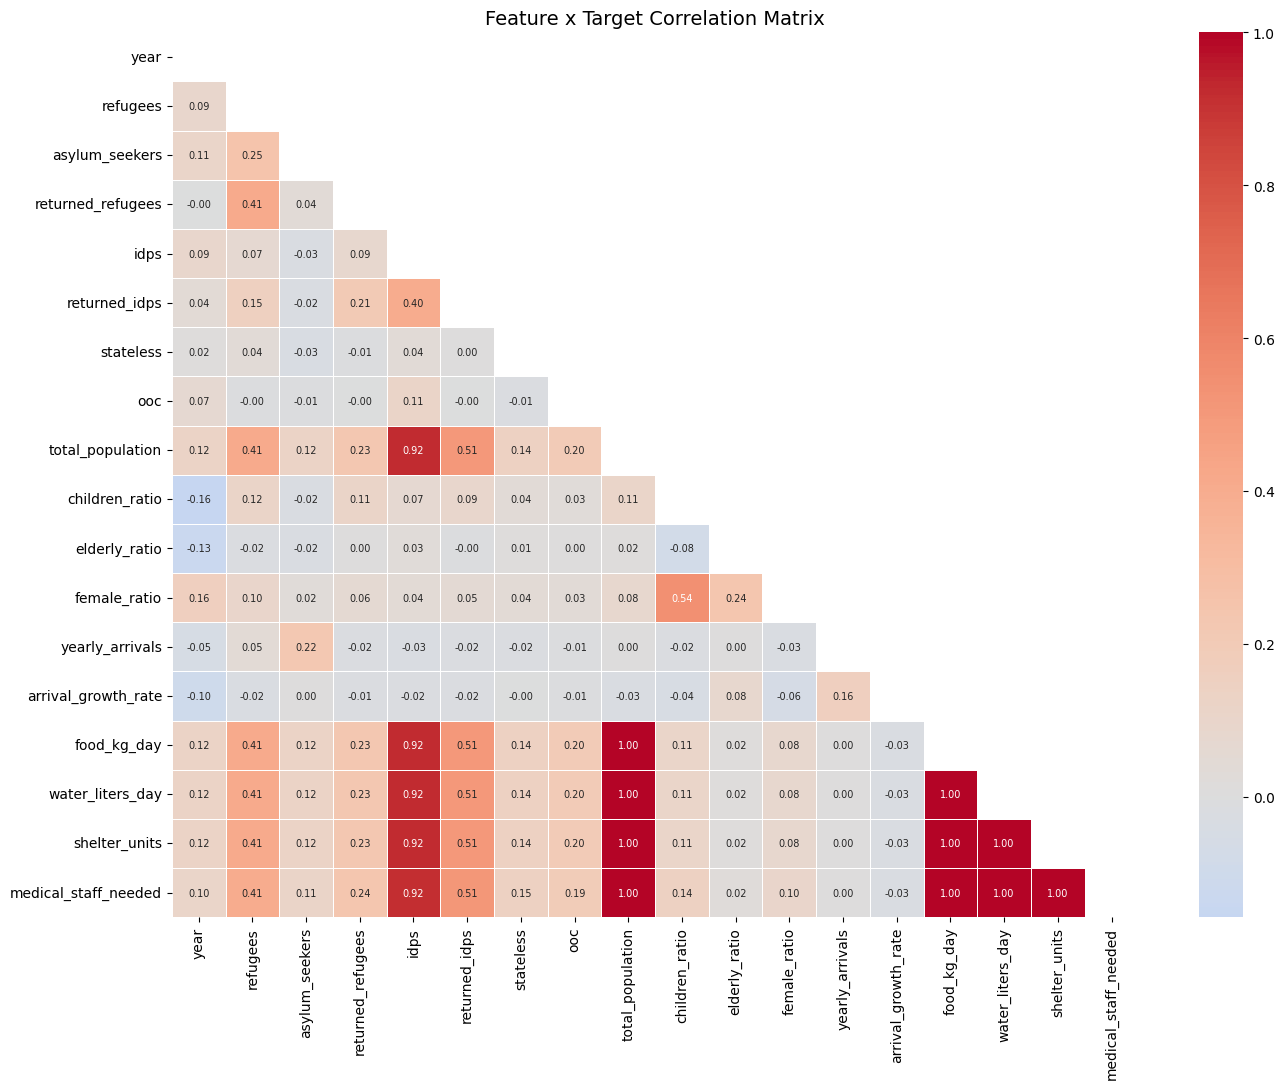

In [15]:
# 9e — Feature correlation heatmap (features + targets)
corr_df = df[FEATURE_COLS + TARGET_COLS].select_dtypes(include='number').corr()
mask    = np.triu(np.ones_like(corr_df, dtype=bool))

fig, ax = plt.subplots(figsize=(14, 11))
sns.heatmap(
    corr_df, mask=mask,
    annot=True, fmt='.2f', cmap='coolwarm',
    center=0, linewidths=0.4, ax=ax,
    annot_kws={'size': 7}
)
ax.set_title('Feature x Target Correlation Matrix', fontsize=14)
plt.tight_layout()
plt.show()

## 10. Save Processed Data

In [16]:
out_path = PROCESSED / 'camp_features.csv'
df.to_csv(out_path, index=False)

print(f'Saved  : {out_path}')
print(f'Shape  : {df.shape}')
print(f'Rows   : {len(df):,}')
print()
print(f'Feature columns ({len(FEATURE_COLS)}):')
for c in FEATURE_COLS:
    print(f'  {c}')
print()
print(f'Target columns ({len(TARGET_COLS)}):')
for c in TARGET_COLS:
    print(f'  {c}')
print()
print('Done. Next: run 02_resource_prediction_model.ipynb')

Saved  : ../data/processed/camp_features.csv
Shape  : (2251, 20)
Rows   : 2,251

Feature columns (14):
  year
  refugees
  asylum_seekers
  returned_refugees
  idps
  returned_idps
  stateless
  ooc
  total_population
  children_ratio
  elderly_ratio
  female_ratio
  yearly_arrivals
  arrival_growth_rate

Target columns (4):
  food_kg_day
  water_liters_day
  shelter_units
  medical_staff_needed

Done. Next: run 02_resource_prediction_model.ipynb
